In [1]:
import pandas as pd


In [2]:
import numpy as np

In [7]:
df=pd.read_csv("titanic.csv")

In [8]:
df.head()


,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [9]:
df.tail()

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
882,0,2,Rev. Juozas Montvila,male,27.0,0,0,13.00
883,1,1,Miss. Margaret Edith Graham,female,19.0,0,0,30.00
884,0,3,Miss. Catherine Helen Johnston,female,7.0,1,2,23.45
885,1,1,Mr. Karl Howell Behr,male,26.0,0,0,30.00
886,0,3,Mr. Patrick Dooley,male,32.0,0,0,7.75


In [11]:
df.shape

(887, 8)

df.columns()

In [13]:
df.columns

Index(['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'Siblings/Spouses Aboard',
       'Parents/Children Aboard', 'Fare'],
      dtype='object')

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Survived                 887 non-null    int64  
 1   Pclass                   887 non-null    int64  
 2   Name                     887 non-null    object 
 3   Sex                      887 non-null    object 
 4   Age                      887 non-null    float64
 5   Siblings/Spouses Aboard  887 non-null    int64  
 6   Parents/Children Aboard  887 non-null    int64  
 7   Fare                     887 non-null    float64
dtypes: float64(2), int64(4), object(2)
memory usage: 55.6+ KB


In [18]:
df['Pclass'].describe()

count    887.000000
mean       2.305524
std        0.836662
min        1.000000
25%        2.000000
50%        3.000000
75%        3.000000
max        3.000000
Name: Pclass, dtype: float64

In [20]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.isna().sum()

Survived                   0
Pclass                     0
Name                       0
Sex                        0
Age                        0
Siblings/Spouses Aboard    0
Parents/Children Aboard    0
Fare                       0
dtype: int64

In [23]:
import matplotlib.pyplot as plt

<Axes: >

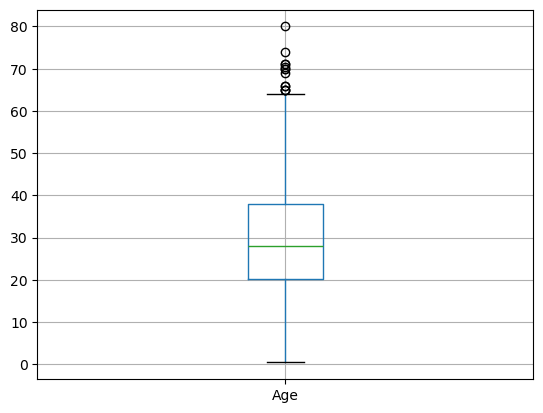

In [26]:
df.boxplot(column='Age')


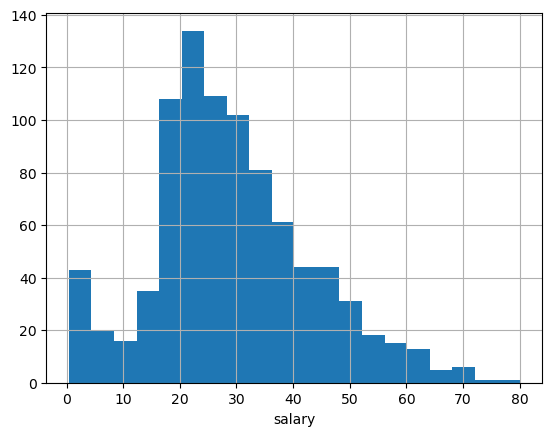

In [31]:
df['Age'].hist(bins=20)
plt.xlabel("salary")

plt.show()

In [33]:
# q1 = df["Age"].quantile(0.25)
# q3 = df["Age"].quantile(0.75)

# iqr = q3 - q1

# lower = q1 - 1.5 * iqr
# upper = q3 + 1.5 * iqr

# outliers = df[
#     (df["Age"] < lower) |
#     (df["Age"] > upper)
# ]

# print(outliers)

In [34]:
from sklearn.preprocessing import LabelEncoder

In [36]:
x=LabelEncoder()
df['Sex']=x.fit_transform(df['Sex'])

In [38]:
df['Age'].skew()

np.float64(0.44718857190799916)

In [45]:
for i in df.select_dtypes(include='integer').columns:
    s=df[i].skew()
    print(f"{i}:{s:.2f}")

Survived:0.47
Pclass:-0.62
Sex:-0.61
Siblings/Spouses Aboard:3.69
Parents/Children Aboard:2.74


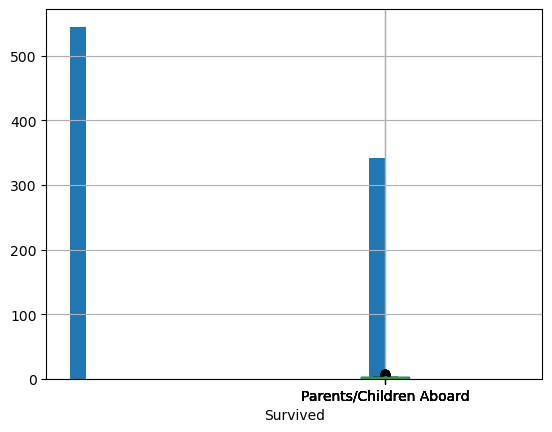

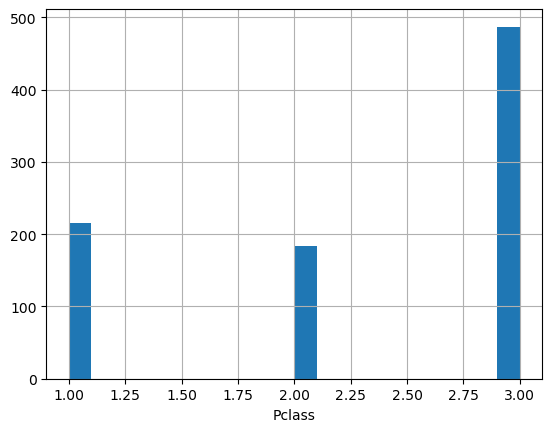

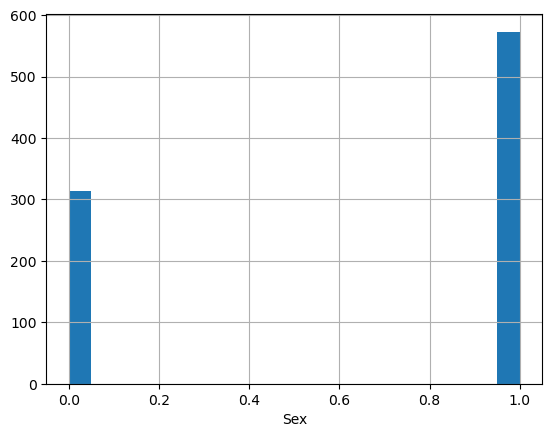

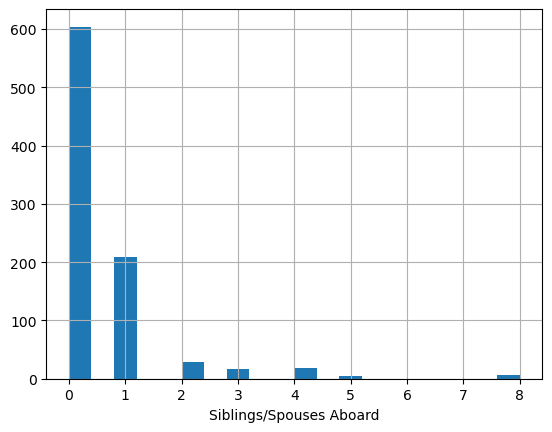

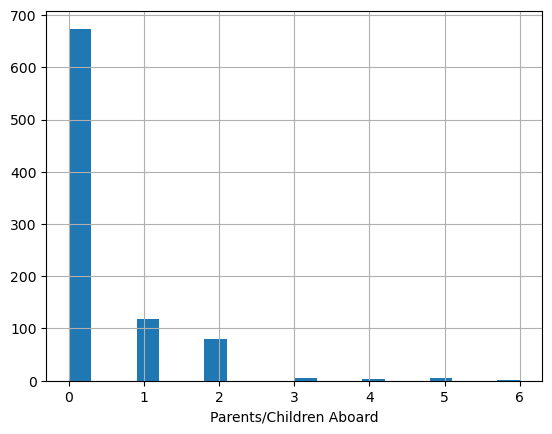

In [54]:
for i in df.select_dtypes(include='integer').columns:
    
    j=df[i].hist(bins=20)
    plt.xlabel(i)
    plt.show()

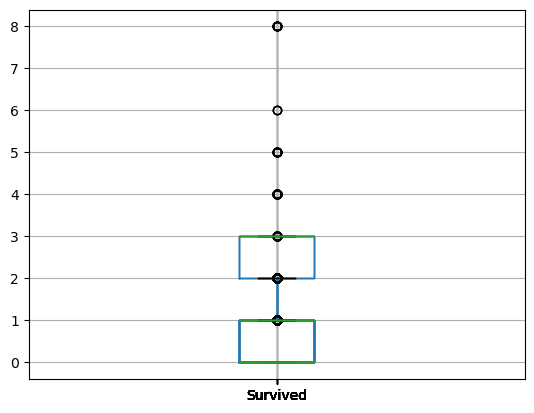

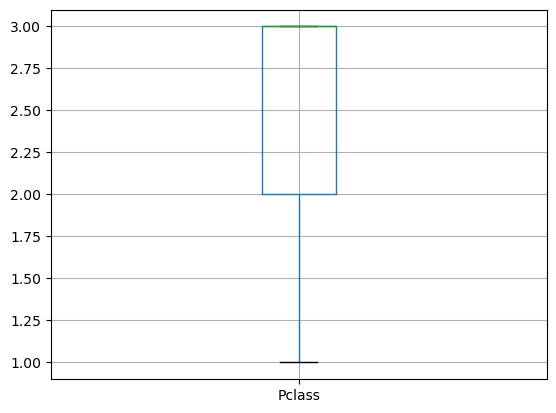

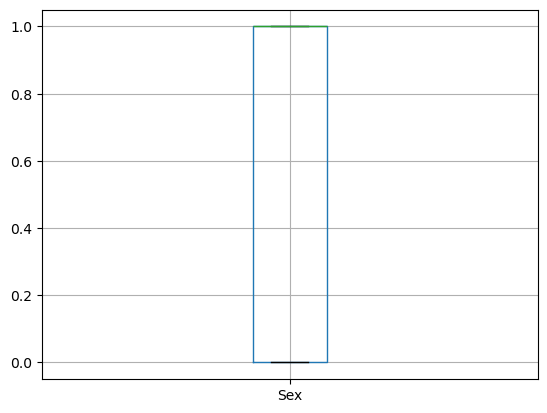

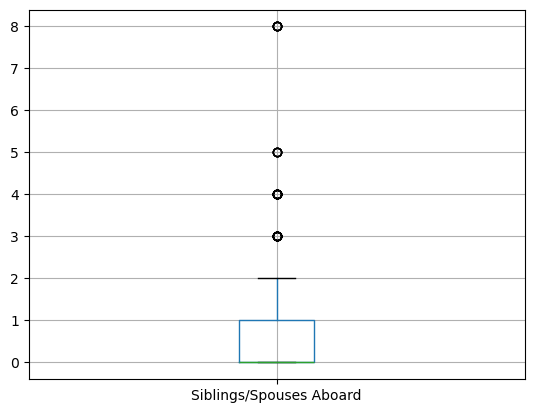

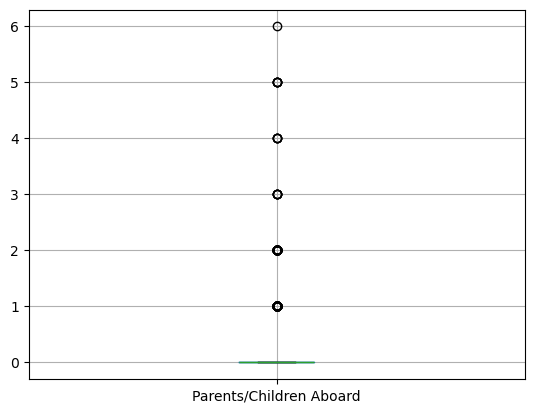

In [58]:
for i in df.select_dtypes(include='integer').columns:
    df.boxplot(column=i)
    plt.show()

In [80]:
x=df.drop(columns=["Survived","Name",])

In [81]:
y=df['Survived']
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Survived                 887 non-null    int64  
 1   Pclass                   887 non-null    int64  
 2   Name                     887 non-null    object 
 3   Sex                      887 non-null    int64  
 4   Age                      887 non-null    float64
 5   Siblings/Spouses Aboard  887 non-null    int64  
 6   Parents/Children Aboard  887 non-null    int64  
 7   Fare                     887 non-null    float64
dtypes: float64(2), int64(5), object(1)
memory usage: 55.6+ KB


from sklearn.model_selection import train_test_split

In [82]:
from sklearn.model_selection import train_test_split

In [83]:
X_train,X_test,Y_train,Y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [84]:
print(X_train.shape)  # (800, 5)
print(X_test.shape)   # (200, 5)
print(Y_train.shape)  # (800,)
print(Y_test.shape)   # (200,)

(709, 6)
(178, 6)
(709,)
(178,)


In [85]:
from sklearn.linear_model import LinearRegression

In [86]:
model=LogisticRegression(max_iter=1000)
model.fit(X_train,Y_train)

LogisticRegression(max_iter=1000)

In [87]:
Y=model.predict(X_test)

In [88]:
from sklearn.metrics import classification_report

In [92]:
print(classification_report(Y_test,Y,zero_division=0))

              precision    recall  f1-score   support

           0       0.81      0.83      0.82       109
           1       0.72      0.68      0.70        69

    accuracy                           0.78       178
   macro avg       0.76      0.76      0.76       178
weighted avg       0.77      0.78      0.77       178

